# ADL Hedge Analysis

Auto-deleveraging (ADL) closes half the short on a spot–perpetual hedge. The spot is still there, so the portfolio is long again. How much of the short would you have to put back to keep the combined loss and trading cost within a fixed limit?

The starting position comes from my article *The Price of Solvency*. The loss limit adds a question the original example leaves open: when would a partial hedge be enough?

In [1]:
# Scenario inputs
adl_price_usd = 90_000
spot_btc = 1.0
initial_short_btc = spot_btc
closure_fractions = (0.0, 0.25, 0.5, 1.0)
example_closed_fraction = 0.5
example_return = -0.05
rehedge_cost_bps = 50
loss_limit_usd = 1_000

## What ADL leaves behind

- **Short closed** = initial short quantity × fraction closed
- **Net BTC exposure** = spot quantity − remaining short quantity
- **Incremental P&L** = net BTC exposure × ADL price × subsequent price return
- **Illustrative re-hedging cost** = short quantity closed × ADL price × cost in basis points ÷ 10,000

The P&L calculation assumes the spot and perpetual move by the same dollar amount per BTC. The cost calculation assumes the short is restored at the ADL price and applies a one-time execution cost. The chart shows price exposure before any new short is added.

In [2]:
def hedge_scenario(close_fraction, subsequent_return):
    closed_short_btc = initial_short_btc * close_fraction
    remaining_short_btc = initial_short_btc - closed_short_btc
    net_btc = spot_btc - remaining_short_btc
    exposure_usd = net_btc * adl_price_usd
    incremental_pnl_usd = exposure_usd * subsequent_return
    rehedge_cost_usd = closed_short_btc * adl_price_usd * rehedge_cost_bps / 10_000
    return remaining_short_btc, net_btc, exposure_usd, incremental_pnl_usd, rehedge_cost_usd


print(f"Incremental P&L after a subsequent {example_return:+.0%} price move")
print(f"{'Closed':>7} {'Short BTC':>10} {'Net BTC':>9} {'Exposure':>12} {'P&L':>12} {'Re-hedge':>12}")
for fraction in closure_fractions:
    remaining, net, exposure, pnl, cost = hedge_scenario(fraction, example_return)
    print(f"{fraction:>7.0%} {remaining:>10.2f} {net:>9.2f} {exposure:>12,.0f} {pnl:>12,.0f} {cost:>12,.0f}")
print("Exposure, P&L, and re-hedging cost are in USD.")

Incremental P&L after a subsequent -5% price move
 Closed  Short BTC   Net BTC     Exposure          P&L     Re-hedge
     0%       1.00      0.00            0           -0            0
    25%       0.75      0.25       22,500       -1,125          112
    50%       0.50      0.50       45,000       -2,250          225
   100%       0.00      1.00       90,000       -4,500          450
Exposure, P&L, and re-hedging cost are in USD.


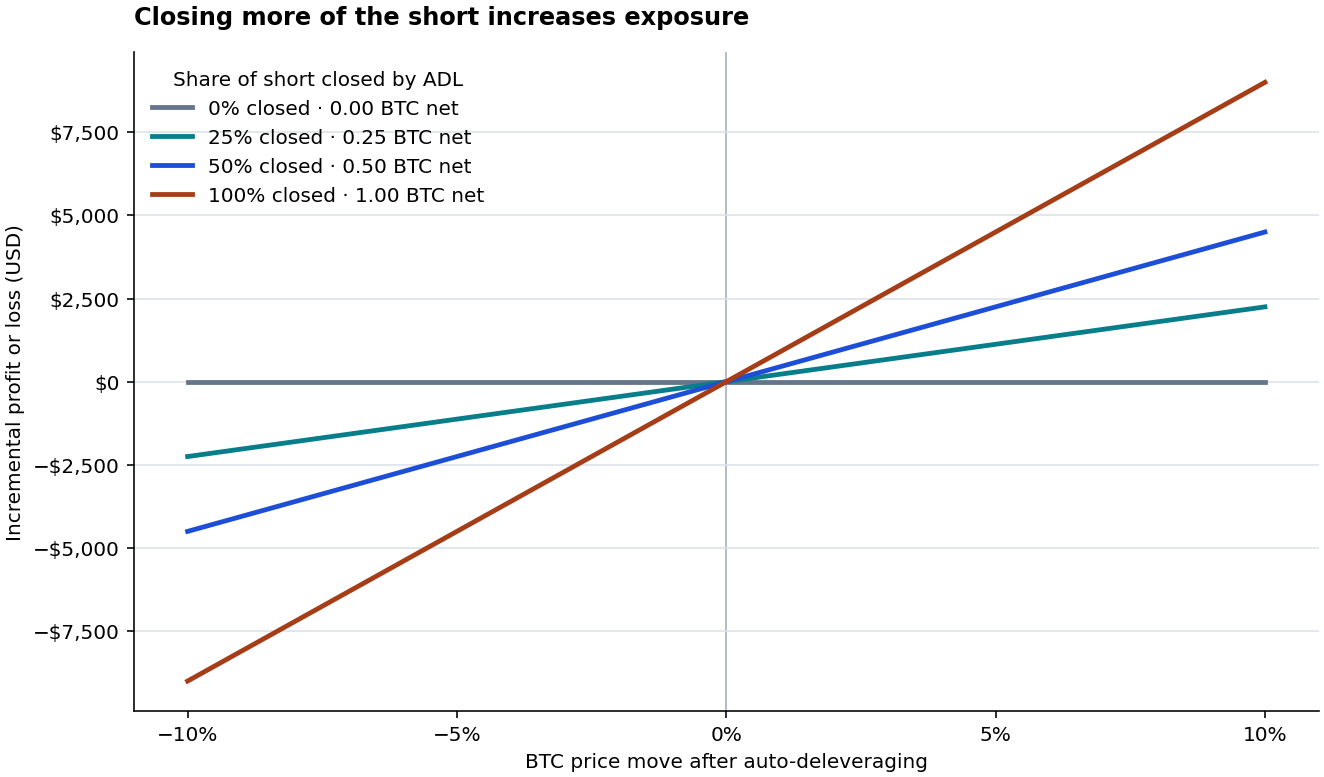

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

price_returns = [step / 100 for step in range(-10, 11)]
colors = ("#65758b", "#087e8b", "#1d4ed8", "#a53d17")

fig, ax = plt.subplots(figsize=(9.2, 5.4), layout="constrained")
for index, fraction in enumerate(closure_fractions):
    color = colors[index % len(colors)]
    pnl_values = [hedge_scenario(fraction, change)[3] for change in price_returns]
    net_btc = hedge_scenario(fraction, 0)[1]
    ax.plot(price_returns, pnl_values, linewidth=2.4, color=color,
            label=f"{fraction:.0%} closed · {net_btc:.2f} BTC net")

ax.set_title("Closing more of the short increases exposure", loc="left", weight="bold", pad=14)
ax.set_xlabel("BTC price move after auto-deleveraging")
ax.set_ylabel("Incremental profit or loss (USD)")
ax.set_xticks([-0.10, -0.05, 0.0, 0.05, 0.10])
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{'−' if value < 0 else ''}${abs(value):,.0f}")
)
ax.axvline(0, color="#a5adba", linewidth=0.8, zorder=0)
ax.grid(axis="y", color="#dce2ea", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Share of short closed by ADL", loc="upper left", frameon=False)

figure_path = Path("figures/hedge-sensitivity.png")
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path, dpi=144, facecolor="white")
plt.show()

## How much of the hedge needs to go back?

Suppose the next move is a 5% drop. Leaving the 0.5 BTC exposure alone costs $2,250 in that scenario. Putting the whole short back costs $225 at the assumed rate. A loss limit lets us work out how much to replace between those two points.

Each BTC of short you add avoids $4,500 of price loss in the 5% scenario and costs $450 to trade. That improves the combined result by $4,050 per BTC added. To get from a $2,250 loss down to a $1,000 limit, you need to make up $1,250, which takes about 0.309 BTC.

In [4]:
from math import isclose


def stress_cost(residual_btc, restored_btc, drop):
    exposed_btc = residual_btc - restored_btc
    price_loss = exposed_btc * adl_price_usd * drop
    execution_cost = restored_btc * adl_price_usd * rehedge_cost_bps / 10_000
    return price_loss, execution_cost, price_loss + execution_cost


def minimum_rehedge(residual_btc, drop, loss_limit):
    _, _, cost_without_repair = stress_cost(residual_btc, 0, drop)
    if cost_without_repair <= loss_limit:
        return 0.0

    _, _, cost_with_full_repair = stress_cost(residual_btc, residual_btc, drop)
    if cost_with_full_repair > loss_limit:
        return None

    savings_per_btc = adl_price_usd * (drop - rehedge_cost_bps / 10_000)
    required = (cost_without_repair - loss_limit) / savings_per_btc
    return min(residual_btc, required)


_, residual_btc, *_ = hedge_scenario(example_closed_fraction, 0)
example_drop = abs(example_return)
print(f"Loss limit: ${loss_limit_usd:,.0f} · Short closed: {residual_btc:.2f} BTC")
print(f"{'BTC drop':>9} {'Short to add':>15} {'Price loss':>13} {'Trade cost':>13} {'Combined':>13}")
for drop in sorted({0.03, example_drop, 0.08}):
    amount = minimum_rehedge(residual_btc, drop, loss_limit_usd)
    if amount is None:
        print(f"{drop:>9.1%}   Limit cannot be met by restoring up to the original short.")
        continue

    price_loss, trade_cost, total = stress_cost(residual_btc, amount, drop)
    assert total <= loss_limit_usd or isclose(total, loss_limit_usd)
    print(f"{drop:>9.1%} {amount:>11.3f} BTC {price_loss:>13,.2f} {trade_cost:>13,.2f} {total:>13,.2f}")
print("Losses and costs are in USD; calculations use unrounded quantities.")

Loss limit: $1,000 · Short closed: 0.50 BTC
 BTC drop    Short to add    Price loss    Trade cost      Combined
     3.0%       0.156 BTC        930.00         70.00      1,000.00
     5.0%       0.309 BTC        861.11        138.89      1,000.00
     8.0%       0.385 BTC        826.67        173.33      1,000.00
Losses and costs are in USD; calculations use unrounded quantities.


At a $1,000 limit, a 3% drop calls for about 0.156 BTC of new short. A drop of 8% calls for about 0.385 BTC. You can change the loss limit or the cost assumption in the first code cell. If leaving the position open and restoring the full short both exceed the limit, a partial hedge also falls short under these assumptions.

This calculation starts after ADL. It assumes the new short fills immediately at the ADL price and that spot and perpetual prices move together. It excludes funding, basis, and ADL settlement effects. The drop is a stress scenario, so the result depends on the size of the move you choose to plan for.